# Итоговый мини-проект
## Обучаемое сжатие изображений

Выполнили: Сальников Никита 932301, Корепанов Дмитрий 932302

## Цель работы

Разработать и исследовать обучаемый нейросетевой кодек для эффективного сжатия изображений с сохранением высокого визуального качества.

## Задачи

1. Изучить современные методы обучаемого сжатия изображений.
2. Разработать и обучить нейросетевой кодек.
3. Сравнить с традиционными и современными кодеками (Например, JPEG).

Как задачи отражены в тетради: задача 1 - раздел "Изученные методы", задача 2 - раздел "Обучение собственного кодека", задача 3 - разделы "Оценка на Kodak" и "Сравнение кодеков".

## Настройка

Тетрадь лежит в `src/experiments/`. Все пути строятся от корня проекта. Тяжелые шаги, которые требуют других окружений, выполнены заранее скриптами и здесь только читаются:

- обучение кодека - `src/scripts/train_hyperprior_kaggle.py` на Kaggle (2x Tesla T4);
- JPEG и WebP - `src/scripts/run_baselines.py`;
- PULSE - `src/scripts/run_pulse.py` (официальный код Microsoft GenCodec, отдельное окружение);
- DiT-IC - `src/scripts/run_dit_ic.py`.

Оценка собственного кодека на Kodak выполняется прямо в тетради.

In [1]:
# Общие импорты, пути и параметры отображения
import os
import sys
import json
import time
import platform
from pathlib import Path

# Корень проекта: тетрадь лежит в src/experiments/
PROJECT_ROOT = Path.cwd().resolve().parents[1]
SRC_ROOT = PROJECT_ROOT / "src"
CACHE_ROOT = SRC_ROOT / "models" / "cache"
# Веса метрик (LPIPS, DISTS, CLIP-IQA, MUSIQ) кешируются внутри проекта
os.environ.setdefault("TORCH_HOME", str(CACHE_ROOT / "torch"))
os.environ.setdefault("XDG_CACHE_HOME", str(CACHE_ROOT))
sys.dont_write_bytecode = True

# Скрываем служебные предупреждения библиотек, которые не влияют на результаты
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

KODAK_DIR = SRC_ROOT / "images" / "kodak"              # тестовый набор
METRICS_DIR = SRC_ROOT / "result" / "metrics"           # CSV с результатами
KAGGLE_DIR = SRC_ROOT / "result" / "hyperprior" / "kaggle"  # веса и журналы обучения с Kaggle
PULSE_DIR = SRC_ROOT / "result" / "pulse"              # реконструкции PULSE
FIGURES_DIR = SRC_ROOT / "result" / "figures" / "project"   # рисунки для презентации
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Крупные шрифты, чтобы рисунки читались на слайдах
plt.rcParams.update({"font.size": 13, "axes.titlesize": 14, "axes.labelsize": 13,
                     "legend.fontsize": 10, "figure.dpi": 110})
pd.set_option("display.precision", 4)

In [2]:
# Версии библиотек и оборудование - для воспроизводимости
import compressai
import pyiqa
import torchmetrics

print("Python     :", platform.python_version())
print("ОС         :", platform.platform())
print("PyTorch    :", torch.__version__, "| CUDA:", torch.version.cuda)
print("CompressAI :", compressai.__version__)
print("pyiqa      :", pyiqa.__version__, "| torchmetrics:", torchmetrics.__version__)
print("GPU        :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "нет")

Python     : 3.12.3
ОС         : Linux-6.18.58.1-microsoft-standard-WSL2-x86_64-with-glibc2.39
PyTorch    : 2.5.0+cu124 | CUDA: 12.4
CompressAI : 1.2.8
pyiqa      : 0.1.14.1 | torchmetrics: 1.8.2
GPU        : NVIDIA GeForce RTX 4070 Laptop GPU


**Результат:** оценка выполнена в WSL2 (Python 3.12.3, PyTorch 2.5.0 с CUDA 12.4, CompressAI 1.2.8, pyiqa 0.1.14.1, torchmetrics 1.8.2) на NVIDIA GeForce RTX 4070 Laptop GPU. Обучение шло на Kaggle: PyTorch 2.11.0, две Tesla T4. При повторном запуске метрики могут отличаться в последних знаках из-за недетерминизма вычислений на GPU (cuDNN).

## Описание наборов данных

Используются два набора, и они не пересекаются: один только для обучения, другой только для проверки.

| Набор | Роль | Что это | Объем |
|---|---|---|---|
| DIV2K (train HR) | обучение | набор фотографий высокого разрешения соревнования NTIRE 2017 (ETH Zurich): природа, люди, город, предметы | 800 изображений, около 2040 пикселей по длинной стороне |
| Kodak (Kodak Lossless True Color Image Suite) | проверка | классический тестовый набор для сжатия изображений: 24 фотографии без потерь | 24 изображения 768x512 или 512x768 |

Почему так: Kodak - общепринятый тест в статьях по сжатию, поэтому наши числа можно сопоставить с опубликованными. Обучение на DIV2K, а проверка на Kodak исключает утечку: модель ни разу не видела тестовые изображения.

DIV2K загружен на Kaggle как публичный набор `soumikrakshit/div2k-high-resolution-images`; тетрадь его не скачивает, количество изображений берется из журнала обучения.

In [3]:
# Анализ тестового набора Kodak: количество, размеры, ориентация, размер PNG
kodak_paths = sorted(KODAK_DIR.glob("*.png"))
records = []
for path in kodak_paths:
    with Image.open(path) as image:
        width, height = image.size
        mode = image.mode
    # PNG сжимает без потерь, поэтому его bpp - "потолок" для сравнения
    png_bpp = path.stat().st_size * 8 / (width * height)
    records.append({"Файл": path.name, "Ширина": width, "Высота": height, "Режим": mode,
                    "Ориентация": "альбомная" if width > height else "книжная",
                    "PNG, bpp": png_bpp})
kodak_info = pd.DataFrame(records)

print("Изображений в Kodak:", len(kodak_info))
print(kodak_info.groupby(["Ширина", "Высота", "Ориентация"]).size().rename("Количество").to_string())
print(f"PNG без потерь: в среднем {kodak_info['PNG, bpp'].mean():.2f} бит на пиксель "
      f"(от {kodak_info['PNG, bpp'].min():.2f} до {kodak_info['PNG, bpp'].max():.2f})")

Изображений в Kodak: 24
Ширина  Высота  Ориентация
512     768     книжная        6
768     512     альбомная     18
PNG без потерь: в среднем 13.05 бит на пиксель (от 10.02 до 16.74)


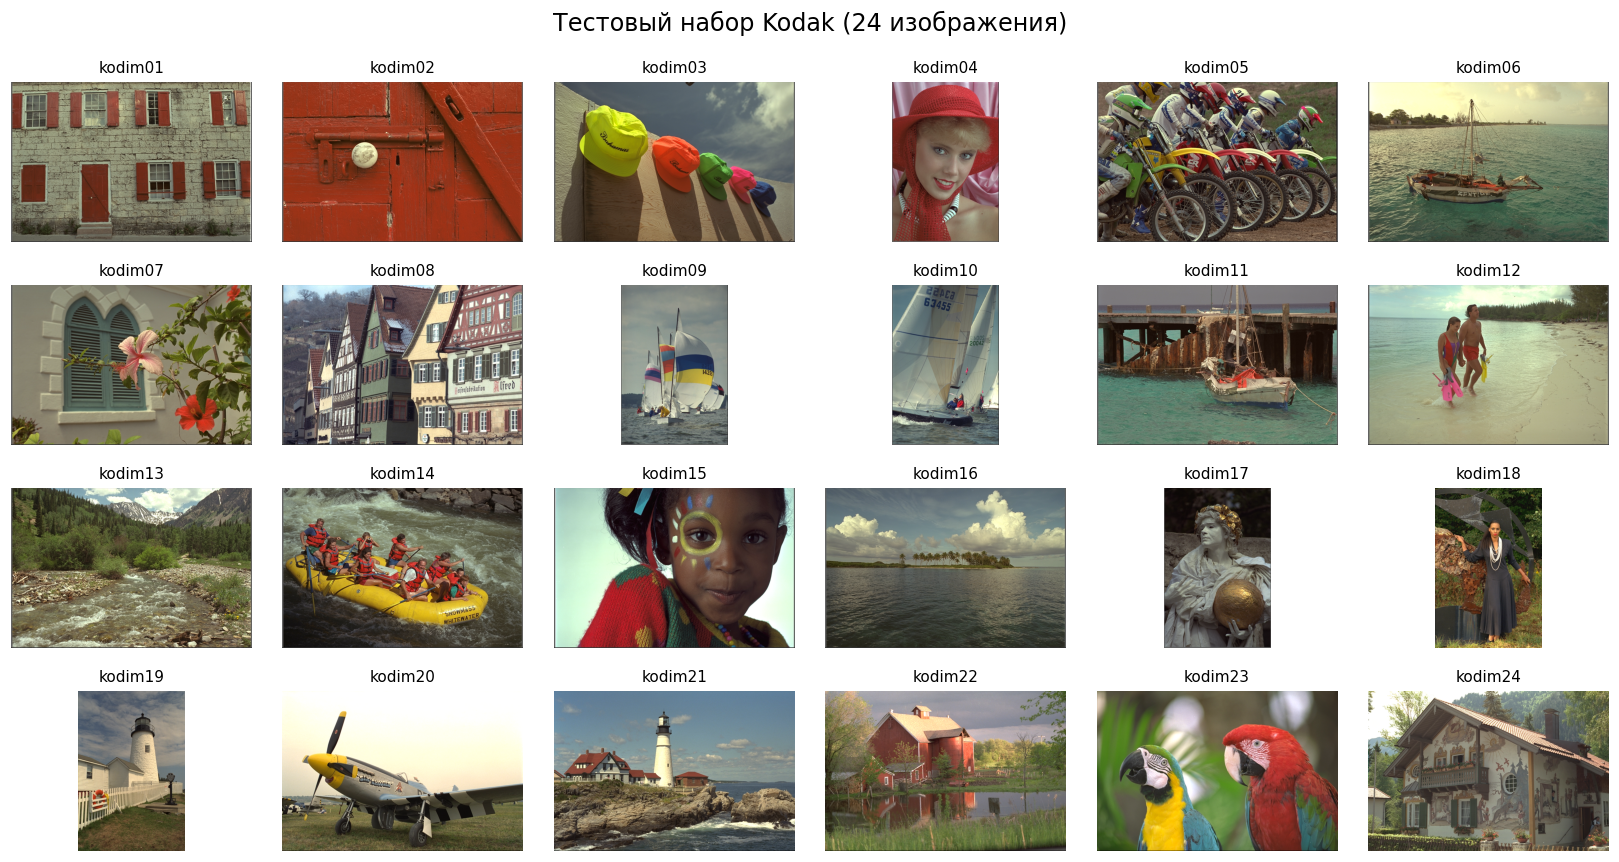

In [4]:
# Все 24 изображения Kodak одной сеткой
fig, axes = plt.subplots(4, 6, figsize=(15, 8))
for axis, path in zip(axes.ravel(), kodak_paths):
    axis.imshow(Image.open(path))
    axis.set_title(path.stem, fontsize=10)
    axis.axis("off")
fig.suptitle("Тестовый набор Kodak (24 изображения)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "kodak-grid.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат:** 24 изображения: 18 альбомных 768x512 и 6 книжных 512x768. Без потерь (PNG) они занимают в среднем 13,05 бит на пиксель (от 10,02 до 16,74), поэтому 0,2 bpp - это сжатие примерно в 65 раз относительно PNG и в 120 раз относительно несжатых 24 бит на пиксель.

## Изученные методы

Сравниваются кодеки трех поколений. Для всех считается реальный размер сжатого файла, а не оценка.

| Кодек | Тип | Идея | Параметров |
|---|---|---|---|
| JPEG | классический (1992) | блочное дискретное косинусное преобразование 8x8 и квантование коэффициентов | нет (ручной алгоритм) |
| WebP | классический (2010) | внутрикадровое предсказание блоков (VP8) и кодирование остатка | нет |
| Scale hyperprior (Balle и др., 2018) | обучаемый, базовый | нейросетевое преобразование в латентное представление и энтропийная модель с "гиперприором", который передает масштаб распределения | 5,1 млн |
| PULSE (Microsoft GenCodec, 2026) | обучаемый, современный | легкий кодек с 8 уровнями качества (QP 0-7) в одной модели; версии MSE (точность пикселей) и perceptual (визуальное качество) | 12,7-19,3 млн |
| DiT-IC (CVPR 2026) | генеративный | сильно сжатый латент, из которого диффузионный трансформер за один шаг дорисовывает изображение | 1 069 млн |

Scale hyperprior выбран как собственный кодек, потому что это базовая архитектура, на которой построены почти все современные обучаемые кодеки (в том числе PULSE), каждый ее блок можно объяснить, и у CompressAI есть официальные веса этой же модели для проверки нашего обучения.

**Как измеряется сжатие.** Битрейт - число бит на пиксель исходного изображения:

$$bpp = \frac{8 \cdot \text{размер файла в байтах}}{W \cdot H}$$

**Как измеряется качество.** Метрики считаются одним и тем же кодом для всех кодеков:

| Метрика | Что показывает | Лучше |
|---|---|---|
| PSNR, дБ | точность пикселей (среднеквадратичная ошибка в логарифмической шкале) | больше |
| MS-SSIM | сходство структуры на нескольких масштабах | больше |
| LPIPS | различие признаков нейросети AlexNet, близко к восприятию человеком | меньше |
| DISTS | различие структуры и текстуры по признакам VGG | меньше |
| CLIP-IQA, MUSIQ | оценка качества без оригинала (насколько изображение "выглядит хорошо") | больше |

## Обучение собственного кодека

### Архитектура

Кодек состоит из четырех сверточных сетей и энтропийного кодера:

- `g_a` (анализ): изображение 3xHxW -> латент y размера 192 x H/16 x W/16;
- `h_a` (гиперанализ): y -> гиперлатент z размера 128 x H/64 x W/64, он передается первым и описывает масштаб (sigma) каждого элемента y;
- `h_s` (гиперсинтез): z -> sigma для гауссовой модели y; по ней арифметический кодер кодирует округленный y;
- `g_s` (синтез): округленный y -> восстановленное изображение.

Нелинейность GDN (generalized divisive normalization) лучше ReLU подходит для сжатия: она "выравнивает" статистику признаков, и латент кодируется короче.

In [5]:
# Создание модели: та же конфигурация, что обучалась на Kaggle (N=128, M=192)
from compressai.models import ScaleHyperprior

model_demo = ScaleHyperprior(N=128, M=192)
blocks = {"g_a (анализ)": model_demo.g_a, "h_a (гиперанализ)": model_demo.h_a,
          "h_s (гиперсинтез)": model_demo.h_s, "g_s (синтез)": model_demo.g_s,
          "энтропийная модель z": model_demo.entropy_bottleneck}
architecture = pd.DataFrame(
    [{"Блок": name, "Параметров": sum(p.numel() for p in block.parameters())} for name, block in blocks.items()]
)
architecture.loc[len(architecture)] = {"Блок": "Всего", "Параметров": sum(p.numel() for p in model_demo.parameters())}
display(architecture)

# Проверка размеров на одном изображении Kodak 768x512
with torch.no_grad():
    x_demo = torch.rand(1, 3, 512, 768)
    y_demo = model_demo.g_a(x_demo)
    z_demo = model_demo.h_a(torch.abs(y_demo))
print("x:", tuple(x_demo.shape), "-> y:", tuple(y_demo.shape), "-> z:", tuple(z_demo.shape))

,Блок,Параметров
0,g_a (анализ),1493312
1,h_a (гиперанализ),1040768
2,h_s (гиперсинтез),1040832
3,g_s (синтез),1493123
4,энтропийная модель z,7808
5,Всего,5075843


x: (1, 3, 512, 768) -> y: (1, 192, 32, 48) -> z: (1, 128, 8, 12)


**Результат:** 5 075 843 веса, из них 59% - в g_a и g_s. Изображение 768x512 превращается в латент 192x32x48 (0,75 числа на пиксель) и гиперлатент 128x8x12 - в 24 раза меньше чисел, чем в y. Число весов совпадает с моделью CompressAI той же конфигурации.

### Функция потерь и обучение

Кодек учится одновременно сжимать сильнее и восстанавливать точнее. Это компромисс "скорость - искажение" (rate-distortion):

$$L = \lambda \cdot 255^2 \cdot \mathrm{MSE}(x, \hat{x}) + R, \qquad R = -\frac{\log_2 p(\hat{y}) + \log_2 p(\hat{z})}{N_{\text{пикселей}}}$$

где R - оценка битрейта (bpp) по вероятностям энтропийной модели, а lambda задает уровень качества: чем больше lambda, тем важнее точность и тем выше битрейт. Обучены 4 модели с lambda = 0,0018; 0,0035; 0,0067; 0,0130 - те же значения, с которыми CompressAI обучала официальные веса качеств 1-4. При обучении округление заменяется добавлением равномерного шума, чтобы градиент проходил.

Обучение шло на Kaggle (две Tesla T4, по одной модели на карту, две сессии параллельно): случайные фрагменты 256x256 из DIV2K, половина из уменьшенных вдвое копий, отражение по горизонтали, Adam с шагом 1e-4 и снижением в 10 раз на 80% времени, отдельный оптимизатор для квантилей энтропийной модели. Ниже - один шаг обучения из скрипта `src/scripts/train_hyperprior_kaggle.py`.

In [6]:
# Листинг шага обучения (метод Run.step скрипта, запускавшегося на Kaggle)
import ast

train_script = (SRC_ROOT / "scripts" / "train_hyperprior_kaggle.py").read_text(encoding="utf-8")
tree = ast.parse(train_script)
for node in ast.walk(tree):
    if isinstance(node, ast.FunctionDef) and node.name == "step":
        print(ast.get_source_segment(train_script, node))

def step(self, batch_uint8: torch.Tensor) -> None:
        x = batch_uint8.to(self.device, non_blocking=True).float().div_(255.0)
        out = self.model(x)
        num_pixels = x.shape[0] * x.shape[2] * x.shape[3]
        bpp = sum(torch.log(l).sum() for l in out["likelihoods"].values()) / (-np.log(2) * num_pixels)
        mse = F.mse_loss(out["x_hat"], x)
        loss = self.lmbda * 255.0**2 * mse + bpp

        self.optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), 1.0)
        self.optimizer.step()

        self.aux_optimizer.zero_grad(set_to_none=True)
        self.model.aux_loss().backward()
        self.aux_optimizer.step()

        self.steps += 1
        # Detached sums; read (and synchronized) only when logging.
        self.window["loss"] += loss.detach()
        self.window["mse"] += mse.detach()
        self.window["bpp"] += bpp.detach()
        self.window["n"] += 1


In [7]:
# Параметры и итоги обучения по журналам Kaggle
run_infos = []
for info_path in sorted(KAGGLE_DIR.glob("night-*/run_info.json")):
    info = json.loads(info_path.read_text())
    for lmbda in info["lambdas"]:
        run_infos.append({
            "lambda": lmbda,
            "Изображений DIV2K": info["images"],
            "Фрагмент": f"{info['crop']}x{info['crop']}",
            "Батч": info["batch"],
            "Шагов": info["steps"],
            "Время, ч": info["train_seconds"] / 3600,
            "Шагов в секунду": info["steps_per_second"],
            "GPU": info["gpus"][0],
            "Память GPU, ГБ": max(info["peak_memory_gb"]),
        })
train_table = pd.DataFrame(run_infos).sort_values("lambda").reset_index(drop=True)
train_table.to_csv(METRICS_DIR / "project-training.csv", index=False)
display(train_table)

,lambda,Изображений DIV2K,Фрагмент,Батч,Шагов,"Время, ч",Шагов в секунду,GPU,"Память GPU, ГБ"
0,0.0018,800,256x256,16,106516,9.0,3.2875,Tesla T4,1.9835
1,0.0035,800,256x256,16,106516,9.0,3.2875,Tesla T4,1.9835
2,0.0067,800,256x256,16,114326,9.0,3.5286,Tesla T4,1.9835
3,0.0130,800,256x256,16,114326,9.0,3.5286,Tesla T4,1.9835


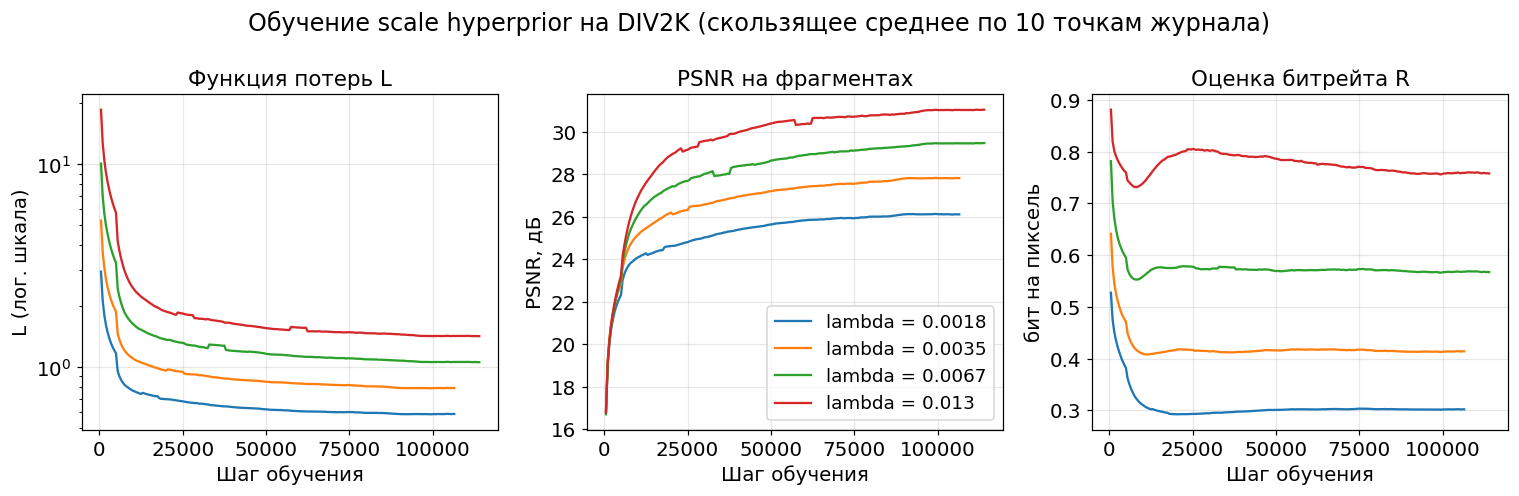

In [8]:
# Кривые обучения: функция потерь, PSNR и битрейт на обучающих фрагментах
logs = pd.concat([pd.read_csv(p) for p in sorted(KAGGLE_DIR.glob("night-*/train_log.csv"))], ignore_index=True)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
for lmbda, part in logs.groupby("lambda"):
    # Скользящее среднее по 10 точкам журнала; сырые значения шумят из-за случайных фрагментов
    smooth = part.set_index("step")[["loss", "psnr", "bpp"]].rolling(10, min_periods=1).mean()
    axes[0].plot(smooth.index, smooth["loss"], label=f"lambda = {lmbda}")
    axes[1].plot(smooth.index, smooth["psnr"], label=f"lambda = {lmbda}")
    axes[2].plot(smooth.index, smooth["bpp"], label=f"lambda = {lmbda}")
axes[0].set_yscale("log")
for axis, title, ylabel in zip(axes, ["Функция потерь L", "PSNR на фрагментах", "Оценка битрейта R"],
                               ["L (лог. шкала)", "PSNR, дБ", "бит на пиксель"]):
    axis.set_title(title)
    axis.set_xlabel("Шаг обучения")
    axis.set_ylabel(ylabel)
    axis.grid(alpha=0.3)
axes[1].legend(fontsize=12)
fig.suptitle("Обучение scale hyperprior на DIV2K (скользящее среднее по 10 точкам журнала)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "training-curves.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат:** За 9 часов каждая модель сделала 106 516 (λ 0,0018 и 0,0035) или 114 326 шагов (λ 0,0067 и 0,013), 3,3-3,5 шага в секунду на одной Tesla T4. Сеть занимает 2,0 ГБ памяти GPU, поэтому две модели обучались параллельно на двух картах одной сессии. Основное улучшение - первые 10-20 тыс. шагов; затем PSNR медленно растет, а оценка битрейта почти постоянна. После снижения шага на 80% времени кривые выходят на плато: для этого рецепта 9 часов близки к пределу. На фрагментах DIV2K битрейт выше, чем на Kodak (0,30-0,76 против 0,15-0,58 bpp): в DIV2K больше мелких деталей.

## Оценка на Kodak

Каждое изображение проходит через настоящий энтропийный кодер: `compress` дает байты, `decompress` восстанавливает изображение только из них. Восстановленные пиксели округляются до 8 бит, как у JPEG/WebP и PULSE. Оцениваются наши 4 модели и официальные веса CompressAI той же архитектуры (качества 1-4).

In [9]:
# Метрики качества: тот же набор и те же реализации, что для всех остальных кодеков
import pyiqa
from torchmetrics.image import LearnedPerceptualImagePatchSimilarity

metrics = {
    "psnr": pyiqa.create_metric("psnr").to(DEVICE).eval(),
    "ms_ssim": pyiqa.create_metric("ms_ssim").to(DEVICE).eval(),
    "dists": pyiqa.create_metric("dists").to(DEVICE).eval(),
    "clipiqa": pyiqa.create_metric("clipiqa").to(DEVICE).eval(),
    "musiq": pyiqa.create_metric("musiq").to(DEVICE).eval(),
    "lpips": LearnedPerceptualImagePatchSimilarity(net_type="alex", normalize=True).to(DEVICE).eval(),
}
METRIC_NAMES = ["psnr", "ms_ssim", "lpips", "dists", "clipiqa", "musiq"]


@torch.no_grad()
def score(reconstruction, original):
    """Все метрики для пары изображений RGB в [0, 1], форма [1, 3, H, W]."""
    return {name: float(metrics[name](reconstruction, original).item()) for name in METRIC_NAMES}

Loading pretrained model DISTS from /home/bigfly/projects/Deep-Image-Compression-ditic/src/models/cache/torch/hub/pyiqa/DISTS_weights-f5e65c96.pth


Loading pretrained model MUSIQ from /home/bigfly/projects/Deep-Image-Compression-ditic/src/models/cache/torch/hub/pyiqa/musiq_koniq_ckpt-e95806b9.pth


In [10]:
# Загрузка моделей: наши веса с Kaggle и официальные веса CompressAI
from compressai.zoo import bmshj2018_hyperprior

ZOO_LAMBDAS = {1: 0.0018, 2: 0.0035, 3: 0.0067, 4: 0.0130}  # качество CompressAI -> lambda обучения

hyperprior_models = []
for checkpoint in sorted(KAGGLE_DIR.glob("night-*/hyperprior_lmbda*.pth")):
    lmbda = float(checkpoint.stem.replace("hyperprior_lmbda", ""))
    # from_state_dict сам берет размеры N, M из весов и готовит буферы энтропийного кодера
    net = ScaleHyperprior.from_state_dict(torch.load(checkpoint, map_location="cpu", weights_only=True))
    hyperprior_models.append(("Hyperprior (наш)", lmbda, net))
# Проверка: ровно одна наша модель на каждое lambda, иначе результаты двух моделей смешались бы
our_lambdas = [lmbda for codec, lmbda, _ in hyperprior_models if codec == "Hyperprior (наш)"]
assert sorted(our_lambdas) == sorted(set(our_lambdas)), f"повтор lambda: {our_lambdas}"
for quality, lmbda in ZOO_LAMBDAS.items():
    net = bmshj2018_hyperprior(quality=quality, metric="mse", pretrained=True)
    hyperprior_models.append(("Hyperprior (CompressAI)", lmbda, net))

for _, _, net in hyperprior_models:
    net.to(DEVICE).eval()
    net.update(force=True)  # целочисленные таблицы распределений для арифметического кодера
print("Моделей для оценки:", len(hyperprior_models))

Моделей для оценки: 8


In [11]:
# Кодирование и декодирование Kodak реальным битовым потоком
SHAPE_HEADER_BYTES = 4  # высота и ширина латента, которые файл тоже должен хранить


def synchronize():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)


@torch.no_grad()
def code_image(net, x):
    """Сжатие в байты и восстановление; возвращает 8-битную реконструкцию, байты и время."""
    height, width = x.shape[-2:]
    # Сеть уменьшает размер в 64 раза, поэтому изображение дополняется до кратного 64
    x_padded = F.pad(x, (0, (-width) % 64, 0, (-height) % 64), mode="replicate")
    synchronize(); t0 = time.perf_counter()
    encoded = net.compress(x_padded)
    synchronize(); encode_ms = (time.perf_counter() - t0) * 1000
    n_bytes = sum(len(s[0]) for s in encoded["strings"]) + SHAPE_HEADER_BYTES
    t0 = time.perf_counter()
    x_hat = net.decompress(encoded["strings"], encoded["shape"])["x_hat"]
    synchronize(); decode_ms = (time.perf_counter() - t0) * 1000
    x_hat = (x_hat[..., :height, :width].clamp(0, 1) * 255).round() / 255
    return x_hat, n_bytes, encode_ms, decode_ms


def to_tensor(image):
    return torch.from_numpy(np.array(image.convert("RGB"))).permute(2, 0, 1)[None].float().div(255)


rows = []
torch.cuda.reset_peak_memory_stats() if DEVICE.type == "cuda" else None
for codec, lmbda, net in hyperprior_models:
    for path in kodak_paths:
        original = to_tensor(Image.open(path)).to(DEVICE)
        reconstruction, n_bytes, encode_ms, decode_ms = code_image(net, original)
        rows.append({"codec": codec, "lmbda": lmbda, "image": path.stem,
                     "bpp": n_bytes * 8 / (original.shape[2] * original.shape[3]), "bytes": n_bytes,
                     "encode_ms": encode_ms, "decode_ms": decode_ms, **score(reconstruction, original)})
hyperprior_rows = pd.DataFrame(rows)
hyperprior_summary = (hyperprior_rows.groupby(["codec", "lmbda"])[["bpp", *METRIC_NAMES, "encode_ms", "decode_ms"]]
                      .mean().reset_index())
# В файлах - те же имена кодеков, что пишет src/scripts/run_hyperprior.py (их читает make_plots.py)
CODEC_IDS = {"Hyperprior (наш)": "hyperprior-ours", "Hyperprior (CompressAI)": "hyperprior-zoo"}
for frame, file_name in ((hyperprior_rows, "hyperprior_kodak.csv"), (hyperprior_summary, "hyperprior_kodak_summary.csv")):
    frame.assign(codec=frame["codec"].map(CODEC_IDS)).to_csv(METRICS_DIR / file_name, index=False)
display(hyperprior_summary[["codec", "lmbda", "bpp", "psnr", "ms_ssim", "lpips", "dists"]])

,codec,lmbda,bpp,psnr,ms_ssim,lpips,dists
0,Hyperprior (CompressAI),0.0018,0.1314,27.5780,0.9271,0.3761,0.2284
1,Hyperprior (CompressAI),0.0035,0.2090,29.1919,0.9502,0.2989,0.1917
2,Hyperprior (CompressAI),0.0067,0.3199,30.9637,0.9674,0.2284,0.1587
3,Hyperprior (CompressAI),0.0130,0.4785,32.8276,0.9797,0.1640,0.1283
4,Hyperprior (наш),0.0018,0.1478,27.2568,0.9282,0.3755,0.2167
5,Hyperprior (наш),0.0035,0.2430,29.0635,0.9513,0.2881,0.1788
6,Hyperprior (наш),0.0067,0.3825,30.8113,0.9698,0.2112,0.1447
7,Hyperprior (наш),0.0130,0.5768,32.8194,0.9819,0.1439,0.1102


In [12]:
# Насколько наше короткое обучение уступает полному: разница PSNR при том же lambda
ours = hyperprior_summary[hyperprior_summary["codec"] == "Hyperprior (наш)"].set_index("lmbda")
zoo = hyperprior_summary[hyperprior_summary["codec"] == "Hyperprior (CompressAI)"].set_index("lmbda")
gap = pd.DataFrame({
    "bpp (наш)": ours["bpp"], "PSNR (наш), дБ": ours["psnr"],
    "bpp (CompressAI)": zoo["bpp"], "PSNR (CompressAI), дБ": zoo["psnr"],
})
# PSNR CompressAI на битрейте нашей модели (линейная интерполяция по кривой CompressAI)
# Вне измеренного диапазона CompressAI интерполяция не определена - там NaN
inside = gap["bpp (наш)"].between(zoo["bpp"].min(), zoo["bpp"].max())
gap["PSNR CompressAI при том же bpp, дБ"] = np.where(
    inside, np.interp(gap["bpp (наш)"], zoo["bpp"], zoo["psnr"]), np.nan)
gap["Отставание, дБ"] = gap["PSNR CompressAI при том же bpp, дБ"] - gap["PSNR (наш), дБ"]
gap.reset_index().to_csv(METRICS_DIR / "project-ours-vs-zoo.csv", index=False)
display(gap)

,bpp (наш),"PSNR (наш), дБ",bpp (CompressAI),"PSNR (CompressAI), дБ","PSNR CompressAI при том же bpp, дБ","Отставание, дБ"
lmbda,,,,,,
0.0018,0.1478,27.2568,0.1314,27.5780,27.9205,0.6636
0.0035,0.2430,29.0635,0.2090,29.1919,29.7348,0.6713
0.0067,0.3825,30.8113,0.3199,30.9637,31.6989,0.8876
0.0130,0.5768,32.8194,0.4785,32.8276,NaN,NaN


**Результат:** При том же λ наши модели тратят на 12-21% больше бит при близком PSNR. При равном битрейте отставание от официальных весов - 0,66-0,89 дБ; для λ 0,013 сравнить нельзя: наш битрейт 0,577 выше наибольшего у CompressAI (0,479). Архитектура одна, поэтому разница - от рецепта обучения: у CompressAI другие данные и расписание шага, у нас 9 часов на T4. По LPIPS и DISTS при том же lambda наши модели даже немного лучше, но только за счет большего битрейта.

## Сравнение кодеков

Результаты остальных кодеков получены на тех же 24 изображениях Kodak и посчитаны тем же кодом метрик (проверено повторным расчетом строки JPEG q50: совпадение до 0,0003). Для JPEG и WebP перебиралась сетка "масштаб x качество" (при очень низком битрейте изображение уменьшается перед сжатием), и на графиках показана лучшая достигнутая точка для каждого битрейта. У PULSE и hyperprior показаны все измеренные точки. Одно отличие в подсчете: метрики DiT-IC (скрипт коллеги) посчитаны по реконструкции до округления пикселей до 8 бит, у остальных кодеков - после.

In [13]:
# Сводная таблица всех кодеков: одна строка - одна рабочая точка (средние по 24 изображениям)
def pareto(frame, metric, higher_is_better):
    """Огибающая лучших значений по битрейту (для сетки JPEG/WebP)."""
    frame = frame.sort_values("bpp")
    best, keep = None, []
    for index, value in frame[metric].items():
        if best is None or (value > best if higher_is_better else value < best):
            best = value
            keep.append(index)
    return frame.loc[keep]


baselines = pd.read_csv(METRICS_DIR / "baselines_kodak_summary.csv")
baselines["codec"] = baselines["codec"].map({"jpeg": "JPEG", "webp": "WebP"})
baselines["setting"] = "масштаб " + baselines["scale"].astype(str) + ", качество " + baselines["quality"].astype(str)

pulse = pd.read_csv(METRICS_DIR / "pulse_kodak_summary.csv")
pulse_names = {"pulse-s-mse": "PULSE-S MSE", "pulse-mse": "PULSE MSE",
               "pulse-perceptual": "PULSE perceptual", "pulse-l-perceptual": "PULSE-L perceptual"}
pulse["codec"] = pulse["codec"].map(pulse_names)
pulse["setting"] = "QP " + pulse["qp"].astype(str)

hyper = hyperprior_summary.copy()
hyper["setting"] = "lambda " + hyper["lmbda"].astype(str)

dit_rows = []
for path in sorted(METRICS_DIR.glob("dit_ic_q*_summary.json")):
    summary = json.loads(path.read_text())
    dit_rows.append({"codec": "DiT-IC", "setting": summary["tag"].replace("dit_ic_", ""),
                     **{key[4:]: summary[key] for key in summary if key.startswith("avg_")}})
dit = pd.DataFrame(dit_rows)

columns = ["codec", "setting", "bpp", *METRIC_NAMES, "encode_ms", "decode_ms"]
all_points = pd.concat([baselines[columns], hyper[columns], pulse[columns], dit[columns]], ignore_index=True)
print("Рабочих точек:", all_points.groupby("codec").size().to_dict())

Рабочих точек: {'DiT-IC': 1, 'Hyperprior (CompressAI)': 4, 'Hyperprior (наш)': 4, 'JPEG': 40, 'PULSE MSE': 8, 'PULSE perceptual': 8, 'PULSE-L perceptual': 8, 'PULSE-S MSE': 8, 'WebP': 40}


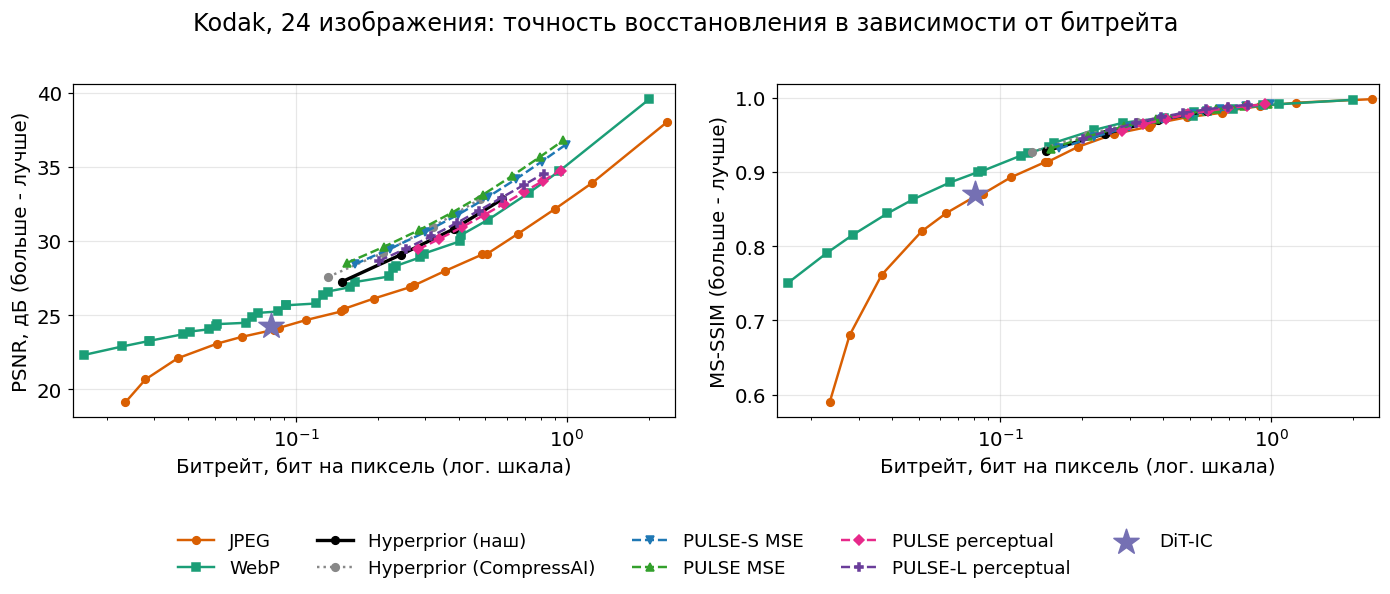

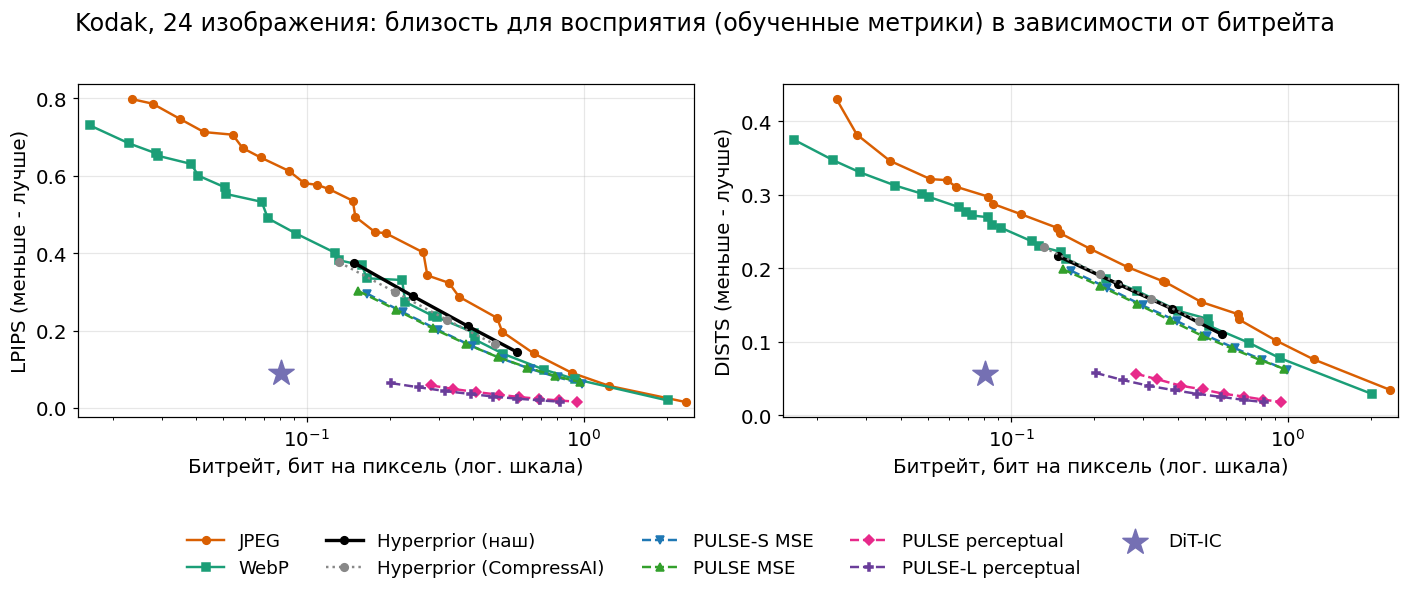

In [14]:
# Кривые "битрейт - качество" для четырех метрик
STYLE = {
    "JPEG": dict(color="#d95f02", marker="o"), "WebP": dict(color="#1b9e77", marker="s"),
    "Hyperprior (наш)": dict(color="black", marker="o", linewidth=2.2),
    "Hyperprior (CompressAI)": dict(color="#888888", marker="o", linestyle=":"),
    "PULSE-S MSE": dict(color="#1f78b4", marker="v", linestyle="--"),
    "PULSE MSE": dict(color="#33a02c", marker="^", linestyle="--"),
    "PULSE perceptual": dict(color="#e7298a", marker="D", linestyle="--"),
    "PULSE-L perceptual": dict(color="#6a3d9a", marker="P", linestyle="--"),
}
PLOTS = [("psnr", "PSNR, дБ (больше - лучше)", True), ("ms_ssim", "MS-SSIM (больше - лучше)", True),
         ("lpips", "LPIPS (меньше - лучше)", False), ("dists", "DISTS (меньше - лучше)", False)]

# Две пары метрик: точность восстановления пикселей и близость для восприятия
FIGURES = [("rd-fidelity.png", "Точность восстановления", PLOTS[:2]),
           ("rd-perceptual.png", "Близость для восприятия (обученные метрики)", PLOTS[2:])]
for file_name, title, plots in FIGURES:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
    for axis, (metric, label, higher) in zip(axes, plots):
        for codec, style in STYLE.items():
            part = all_points[all_points["codec"] == codec]
            if codec in ("JPEG", "WebP"):
                part = pareto(part, metric, higher)
            part = part.sort_values("bpp")
            axis.plot(part["bpp"], part[metric], markersize=5, label=codec, **{"linewidth": 1.6, **style})
        axis.scatter(dit["bpp"], dit[metric], marker="*", s=300, color="#7570b3", zorder=5, label="DiT-IC")
        axis.set_xscale("log")
        axis.set_xlim(0.015, 2.5)
        axis.set_xlabel("Битрейт, бит на пиксель (лог. шкала)")
        axis.set_ylabel(label)
        axis.grid(alpha=0.3)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=5, frameon=False, fontsize=12)
    fig.suptitle(f"Kodak, 24 изображения: {title.lower()} в зависимости от битрейта")
    fig.tight_layout(rect=(0, 0.16, 1, 0.97))
    fig.savefig(FIGURES_DIR / file_name, dpi=150, bbox_inches="tight")
    plt.show()

**Результат:** При равном битрейте наш кодек лучше JPEG на 1,9-2,6 дБ и WebP на 0,5-1,0 дБ (0,15-0,4 bpp), но уступает CompressAI 0,7-0,9 дБ и PULSE MSE около 1,2 дБ. По MS-SSIM все кодеки, кроме JPEG, почти совпадают. По LPIPS и DISTS наш кодек на уровне WebP (LPIPS 0,328 против 0,332 при 0,2 bpp). PULSE perceptual дает LPIPS 0,035-0,046 при 0,3-0,4 bpp - в 3,5-6 раз ниже кодеков на MSE; DiT-IC при 0,08 bpp (LPIPS 0,091) лучше любого MSE-кодека даже при 0,5 bpp.

In [15]:
# Таблица при сопоставимом битрейте: для каждого кодека - измеренная точка, ближайшая к цели
def nearest(frame, target):
    return frame.loc[(frame["bpp"] - target).abs().idxmin()]


tables = {}
for target in (0.1, 0.2, 0.4):
    picked = []
    for codec in all_points["codec"].unique():
        part = all_points[all_points["codec"] == codec]
        # У JPEG/WebP много настроек; настройка, которую другая превосходит при меньшем битрейте,
        # не берется (выбор только из огибающей по PSNR)
        if codec in ("JPEG", "WebP"):
            part = pareto(part, "psnr", True)
        picked.append(nearest(part, target))
    table = pd.DataFrame(picked)[["codec", "setting", "bpp", "psnr", "ms_ssim", "lpips", "dists"]]
    # Точки дальше 30% от цели не считаются сопоставимыми
    table = table[(table["bpp"] - target).abs() <= 0.3 * target].sort_values("psnr", ascending=False)
    table.columns = ["Кодек", "Настройка", "bpp", "PSNR, дБ", "MS-SSIM", "LPIPS", "DISTS"]
    tables[target] = table.reset_index(drop=True)
    print(f"\nЦелевой битрейт около {target} bpp (допуск 30%):")
    display(tables[target])
# Все три таблицы в один файл для презентации
pd.concat([t.assign(**{"Цель, bpp": target}) for target, t in tables.items()]).to_csv(
    METRICS_DIR / "project-matched.csv", index=False)


Целевой битрейт около 0.1 bpp (допуск 30%):


,Кодек,Настройка,bpp,"PSNR, дБ",MS-SSIM,LPIPS,DISTS
0,WebP,"масштаб 0.7, качество 1",0.0919,25.6643,0.8844,0.4516,0.2640
1,JPEG,"масштаб 0.35, качество 30",0.1092,24.6768,0.8925,0.5764,0.2734
2,DiT-IC,q3,0.0805,24.2451,0.8708,0.0911,0.0554



Целевой битрейт около 0.2 bpp (допуск 30%):


,Кодек,Настройка,bpp,"PSNR, дБ",MS-SSIM,LPIPS,DISTS
0,PULSE MSE,QP 1,0.2103,29.5947,0.9477,0.2539,0.1758
1,PULSE-S MSE,QP 1,0.2222,29.4688,0.9472,0.2476,0.1737
2,Hyperprior (CompressAI),lambda 0.0035,0.2090,29.1919,0.9502,0.2989,0.1917
3,Hyperprior (наш),lambda 0.0035,0.2430,29.0635,0.9513,0.2881,0.1788
4,PULSE-L perceptual,QP 0,0.2022,28.6492,0.9447,0.0640,0.0576
5,WebP,"масштаб 0.5, качество 50",0.2211,27.6093,0.9563,0.3306,0.1860
6,JPEG,"масштаб 0.5, качество 30",0.1933,26.1137,0.9336,0.4512,0.2265



Целевой битрейт около 0.4 bpp (допуск 30%):


,Кодек,Настройка,bpp,"PSNR, дБ",MS-SSIM,LPIPS,DISTS
0,Hyperprior (CompressAI),lambda 0.013,0.4785,32.8276,0.9797,0.1640,0.1283
1,PULSE MSE,QP 3,0.3762,31.9099,0.9709,0.1657,0.1292
2,PULSE-S MSE,QP 3,0.3967,31.7798,0.9708,0.1591,0.1283
3,PULSE-L perceptual,QP 3,0.3924,31.2210,0.9738,0.0358,0.0337
4,PULSE perceptual,QP 2,0.4097,30.9361,0.9714,0.0410,0.0403
5,Hyperprior (наш),lambda 0.0067,0.3825,30.8113,0.9698,0.2112,0.1447
6,WebP,"масштаб 0.7, качество 50",0.4019,29.9729,0.9728,0.1944,0.1421
7,JPEG,"масштаб 0.7, качество 30",0.3548,27.9813,0.9609,0.2874,0.1823


**Результат:** в таблицах - измеренные точки, ближайшие к цели, поэтому битрейты кодеков немного различаются; сравнение при строго равном битрейте дают кривые выше. До 0,1 bpp из обучаемых кодеков доходит только DiT-IC: минимум нашего кодека 0,148, CompressAI 0,131, PULSE 0,154 bpp. По PSNR DiT-IC уступает WebP (24,25 против 25,66 дБ), но его LPIPS 0,091 в 5 раз ниже - он дорисовывает правдоподобные детали. При 0,2 bpp: лучший PSNR у PULSE MSE (29,59 дБ). Битрейты в таблице немного различаются: наш кодек дает 29,06 дБ при 0,243 bpp, а при равных 0,2 bpp он выше WebP на 0,8 дБ и JPEG на 2,1 дБ. PULSE-L perceptual теряет около 1 дБ PSNR, но его LPIPS 0,064 в 4-7 раз ниже остальных. При 0,4 bpp: первая строка CompressAI получена при 0,479 bpp - на 20% больше бит, чем у соседей; при равных 0,4 bpp впереди PULSE MSE (32,16 против 31,90 дБ). При равных 0,4 bpp наш кодек (31,0 дБ) лучше WebP на 1,0 дБ и JPEG на 2,6 дБ.

### Визуальное сравнение

Один и тот же фрагмент изображения Kodak при сопоставимом битрейте, в исходном масштабе пикселей. Для каждого кодека берется та настройка, при которой битрейт именно этого изображения ближе всего к цели (у разных изображений при одной настройке битрейт разный). Под каждым фрагментом - битрейт всего изображения.

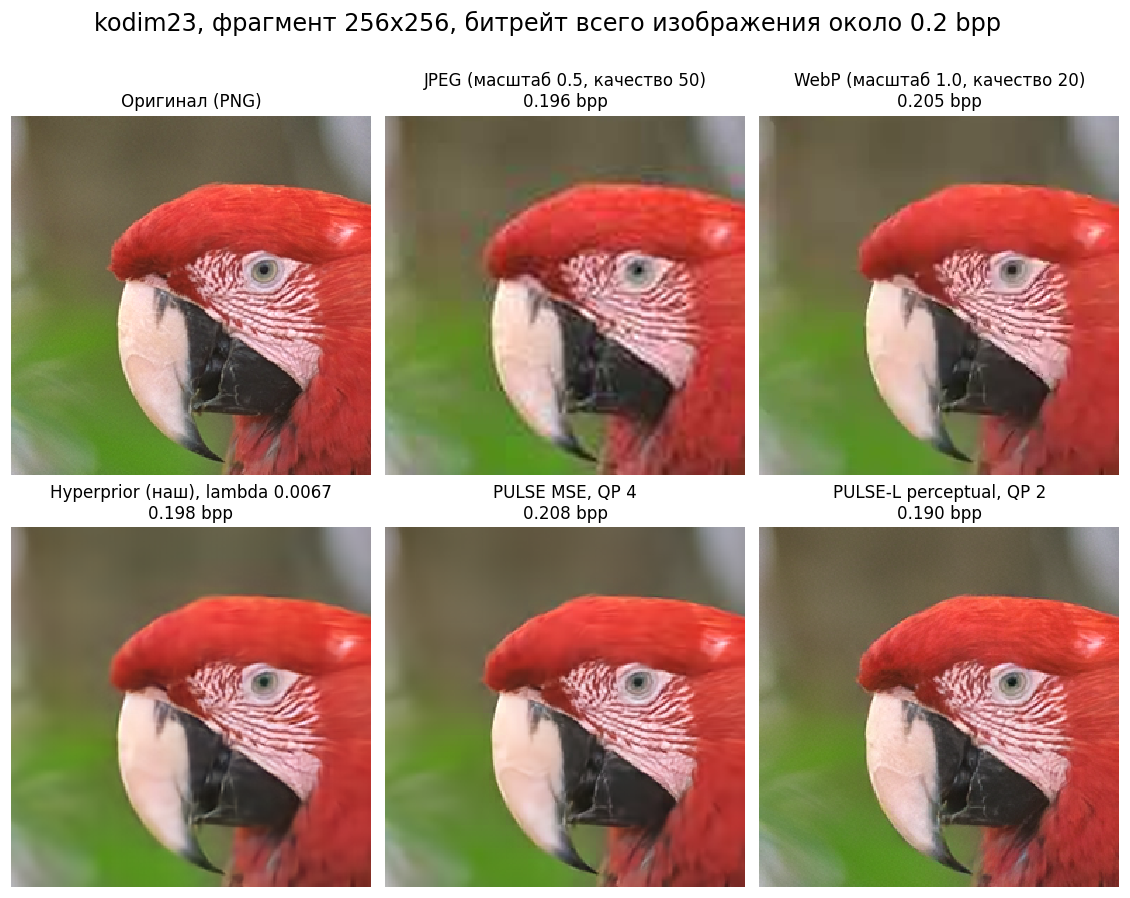

In [16]:
# Фрагмент kodim23 (попугаи: мелкие перья и гладкий фон) при битрейте около 0.2 bpp
import io

IMAGE_NAME, TARGET_BPP = "kodim23", 0.2
CROP = (330, 60, 330 + 256, 60 + 256)  # left, top, right, bottom
original_image = Image.open(KODAK_DIR / f"{IMAGE_NAME}.png").convert("RGB")


NUM_PIXELS = original_image.size[0] * original_image.size[1]
# У каждого изображения свой битрейт при одной настройке, поэтому настройка
# выбирается по битрейту именно этого изображения, а не по среднему по Kodak.


def classic_codec(image, codec):
    """JPEG/WebP: перебор всей сетки "масштаб x качество" на этом изображении, ближайший к цели битрейт."""
    best = None
    for _, row in baselines[baselines["codec"] == codec].iterrows():
        small = image if row["scale"] == 1.0 else image.resize(
            (round(image.size[0] * row["scale"]), round(image.size[1] * row["scale"])), Image.Resampling.LANCZOS)
        buffer = io.BytesIO()
        small.save(buffer, format="JPEG" if codec == "JPEG" else "WEBP", quality=int(row["quality"]))
        bpp = len(buffer.getvalue()) * 8 / NUM_PIXELS
        if best is None or abs(bpp - TARGET_BPP) < abs(best[1] - TARGET_BPP):
            restored = Image.open(io.BytesIO(buffer.getvalue())).convert("RGB").resize(image.size, Image.Resampling.LANCZOS)
            best = (restored, bpp, row["setting"])
    return best


panels = [("Оригинал (PNG)", original_image, None)]
for codec in ("JPEG", "WebP"):
    restored, bpp, setting = classic_codec(original_image, codec)
    panels.append((f"{codec} ({setting})", restored, bpp))

# Наш hyperprior: модель, у которой битрейт kodim23 ближе всего к цели
ours_image = hyperprior_rows[(hyperprior_rows["codec"] == "Hyperprior (наш)") & (hyperprior_rows["image"] == IMAGE_NAME)]
best_lmbda = ours_image.loc[(ours_image["bpp"] - TARGET_BPP).abs().idxmin(), "lmbda"]
net = next(n for c, l, n in hyperprior_models if c == "Hyperprior (наш)" and l == best_lmbda)
restored_tensor, n_bytes, _, _ = code_image(net, to_tensor(original_image).to(DEVICE))
restored = Image.fromarray((restored_tensor[0].permute(1, 2, 0).cpu().numpy() * 255).round().astype(np.uint8))
panels.append((f"Hyperprior (наш), lambda {best_lmbda}", restored, n_bytes * 8 / NUM_PIXELS))

# PULSE: сохраненная реконструкция того QP, у которого битрейт kodim23 ближе всего к цели
pulse_rows = pd.read_csv(METRICS_DIR / "pulse_kodak.csv")
for model, name in (("pulse-mse", "PULSE MSE"), ("pulse-l-perceptual", "PULSE-L perceptual")):
    rows_image = pulse_rows[(pulse_rows["codec"] == model) & (pulse_rows["image"] == IMAGE_NAME)]
    picked = rows_image.loc[(rows_image["bpp"] - TARGET_BPP).abs().idxmin()]
    qp = int(picked["qp"])
    restored = Image.open(PULSE_DIR / model / "rec" / f"qp{qp}" / f"{IMAGE_NAME}.png").convert("RGB")
    panels.append((f"{name}, QP {qp}", restored, float(picked["bpp"])))

fig, axes = plt.subplots(2, 3, figsize=(13, 9.2), gridspec_kw={"hspace": 0.12, "wspace": 0.04})
for axis, (title, image, bpp) in zip(axes.ravel(), panels):
    axis.imshow(image.crop(CROP), interpolation="nearest")
    axis.set_title(title if bpp is None else f"{title}\n{bpp:.3f} bpp", fontsize=11)
    axis.axis("off")
fig.suptitle(f"{IMAGE_NAME}, фрагмент 256x256, битрейт всего изображения около {TARGET_BPP} bpp")
fig.savefig(FIGURES_DIR / "visual-crops.png", dpi=150, bbox_inches="tight")
plt.show()

**Результат:** У JPEG видны блоки и ореолы, у WebP сглажены полосы перьев. Наш кодек и PULSE MSE сохраняют полосы и контуры, слегка размывая фон. PULSE-L perceptual возвращает зернистую текстуру и ближе всех к оригиналу на глаз, хотя по PSNR ниже. Для kodim23 битрейту 0,2 bpp соответствует наша модель с lambda 0,0067: это изображение проще среднего по Kodak.

In [17]:
# Сложность моделей: число весов, время кодирования и декодирования одного изображения Kodak
complexity = pd.DataFrame([
    {"Кодек": "JPEG / WebP", "Весов, млн": 0.0, "Кодирование, мс": baselines["encode_ms"].median(),
     "Декодирование, мс": baselines["decode_ms"].median(), "Где измерено": "CPU (Pillow), машина коллеги"},
    {"Кодек": "Hyperprior (наш)", "Весов, млн": sum(p.numel() for p in model_demo.parameters()) / 1e6,
     "Кодирование, мс": hyperprior_rows[hyperprior_rows["codec"] == "Hyperprior (наш)"]["encode_ms"].median(),
     "Декодирование, мс": hyperprior_rows[hyperprior_rows["codec"] == "Hyperprior (наш)"]["decode_ms"].median(),
     "Где измерено": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"},
])
# Число весов PULSE прочитано из файлов model.pt (вместе с буферами), время - из run_pulse.py (RTX 4070 Laptop)
pulse_weights = {"PULSE-S MSE": 12.67, "PULSE MSE": 14.72, "PULSE perceptual": 14.72, "PULSE-L perceptual": 19.29}
pulse_times = pd.read_csv(METRICS_DIR / "pulse_kodak.csv").assign(codec=lambda d: d["codec"].map(pulse_names))
for name, weights in pulse_weights.items():
    part = pulse_times[pulse_times["codec"] == name]
    complexity.loc[len(complexity)] = {"Кодек": name, "Весов, млн": weights,
                                       "Кодирование, мс": part["encode_ms"].median(),
                                       "Декодирование, мс": part["decode_ms"].median(),
                                       "Где измерено": "NVIDIA GeForce RTX 4070 Laptop GPU"}
dit_summary = json.loads((METRICS_DIR / "dit_ic_q3_summary.json").read_text())
complexity.loc[len(complexity)] = {"Кодек": "DiT-IC", "Весов, млн": dit_summary["parameters_b"] * 1000,
                                   "Кодирование, мс": dit_summary["median_encode_ms"],
                                   "Декодирование, мс": dit_summary["median_decode_ms"],
                                   "Где измерено": dit_summary["gpu"] + ", машина коллеги"}
complexity.to_csv(METRICS_DIR / "project-complexity.csv", index=False)
display(complexity)

,Кодек,"Весов, млн","Кодирование, мс","Декодирование, мс",Где измерено
0,JPEG / WebP,0.0000,2.3214,7.1068,"CPU (Pillow), машина коллеги"
1,Hyperprior (наш),5.0758,28.7971,37.6158,NVIDIA GeForce RTX 4070 Laptop GPU
2,PULSE-S MSE,12.6700,86.3193,33.8464,NVIDIA GeForce RTX 4070 Laptop GPU
3,PULSE MSE,14.7200,68.4664,33.6144,NVIDIA GeForce RTX 4070 Laptop GPU
4,PULSE perceptual,14.7200,82.7454,43.4543,NVIDIA GeForce RTX 4070 Laptop GPU
5,PULSE-L perceptual,19.2900,101.8479,80.5913,NVIDIA GeForce RTX 4070 Laptop GPU
6,DiT-IC,1069.4112,277.6011,391.8151,"NVIDIA GeForce RTX 5060 Ti, машина коллеги"


**Результат:** Наш кодек - самый легкий из обучаемых: 5,1 млн весов, 29 мс на кодирование и 38 мс на декодирование изображения Kodak на ноутбучной RTX 4070. PULSE в 2,5-4 раза больше, кодирует в 2,4-3,5 раза медленнее, декодирует так же или до 2 раз медленнее; DiT-IC больше в 200 раз и медленнее примерно в 10 раз. Машины разные, поэтому сравнение - по порядку величины.

## Вывод

1. **Изученные методы.** Изучены три направления обучаемого сжатия и устройство вариационного кодека с гиперприором. Для сравнения выбраны кодеки трех типов: классические JPEG и WebP, обучаемые на MSE scale hyperprior и PULSE, генеративный DiT-IC; качество оценено шестью метриками по реальному размеру файла.

2. **Собственный кодек.** Собственный кодек scale hyperprior (5,08 млн весов) обучен с нуля на DIV2K: 4 модели λ 0,0018-0,013, по 9 часов на Tesla T4 (106-114 тыс. шагов). На Kodak реальный битовый поток дает 0,148-0,577 bpp при PSNR 27,26-32,82 дБ; до официальных весов той же сети не хватает 0,66-0,89 дБ при равном битрейте.

3. **Сравнение.** При равном битрейте наш кодек лучше JPEG на 1,9-2,6 дБ PSNR и WebP на 0,5-1,0 дБ, по MS-SSIM, LPIPS и DISTS он на уровне WebP. Лучший по PSNR - PULSE MSE, по восприятию - PULSE perceptual (LPIPS 0,035-0,046) и DiT-IC (LPIPS 0,091 при 0,08 bpp). Цель достигнута частично: кодек обходит традиционные, но для высокого визуального качества при низком битрейте нужна функция потерь с учетом восприятия - следующий шаг.

4. **Почему так.** Кодеки на MSE усредняют детали, которые нельзя передать, поэтому выигрывают по PSNR и проигрывают по LPIPS; кодеки на восприятие и генеративные дорисовывают текстуру. Обучаемые нелинейные преобразования и энтропийная модель с гиперприором сжимают лучше фиксированного DCT. Разница с официальными весами той же сети объясняется рецептом обучения, а не архитектурой.